In [73]:
import emcee
import numpy as np
import matplotlib.pyplot as plt
import copy
import importlib
import os
from astropy.io import fits
import scipy.constants as sc

In [74]:

np.random.seed(100)

## 1. Set up Model Parameters

In [75]:
datapath          = 'SigOriData/'
obs_measurement_set            = f'{datapath}SO1152_12CO.ms.contsub_lsrk_avg'
mdict_name_prefix = f"{datapath}SO1152_12CO"
outname           = f'{datapath}SO1152_init_walker'
rest_freq_Hz      = 345.7959899e9
rest_freq_GH_str  = '345.7959899GHz'
dist              = 391.3        # pc
vra               = [7e3, 1.8e4] # velocity range for fitdata [m/s]
Nwalk             = 1 # number of walkers for MCMC (1 for test)

### A. Generate Model Structure using Random Priors

In [4]:

priors = importlib.import_module('priors_CSALT0_SDJ')
Ndim = len(priors.pri_pars)
p0 = np.empty((Nwalk, Ndim))

name_to_idx = {name: i for i, name in enumerate(priors.priors_dict)} 
        
for ix in range(Ndim):
    if priors.pri_types[ix] == "linewidth":
                temp_idx = name_to_idx["Tb_10"] # what id is Tb_10, in case not ix=9

                Tmin, Tmax = priors.pri_pars[temp_idx]
            
                thermal_width_min = np.sqrt(
                    2 * sc.k * Tmin /
                    (28 * (sc.m_p + sc.m_e))
                    )
                thermal_width_max = np.sqrt(
                    2 * sc.k * Tmax /
                    (28 * (sc.m_p + sc.m_e))
                    )

                #sample randomly from deltav_min to deltav_max 
                p0[:, ix] = np.random.uniform(
                    low=thermal_width_min,
                    high=thermal_width_max,
                    size=Nwalk)
                
#            if ix == 9:
#                p0[:,ix] = np.sqrt(2 * sc.k * p0[:,6] / (28 * (sc.m_p+sc.m_e)))
    else:
                _ = [str(priors.pri_pars[ix][ip])+', '
                     for ip in range(len(priors.pri_pars[ix]))]
                cmd = 'np.random.'+priors.pri_types[ix]+ \
                      '('+"".join(_)+str(Nwalk)+')'
                try: 
                    p0[:,ix] = eval(cmd)
                except AttributeError: 
                    pass 

theta = p0[0]


# Print the init parameters clearly
param_names = list(priors.priors_dict.keys())

param_names = list(priors.priors_dict.keys())
print("--- First walker initial parameters ---")
for name, val in zip(param_names, theta):
    print(f"  {name:>12s} = {val:.4f}")

--- First walker initial parameters ---
           inc = 65.4500
            PA = 325.0028
         mstar = 0.7519
           z_1 = 0.4224
           z_q = 1.3972
         Tb_10 = 44.6072
          Tb_q = -0.3486
         z_tap = 119.3581
         z_exp = 10.8555
     logtau_10 = 0.3707
         tau_q = -3.4581
       tau_tap = 101.7958
       tau_exp = 10.9849
          vlsr = 12211.4984
            dx = -0.0439
            dy = -0.0501


### B. Generate Model Structure using Preset Parameters

In [95]:
theta = np.array([66.458, 324.447, 0.533, 0.158, 0.693, 
                  56.513, -0.186, 110.083, 4.965, 
                  4.909, 0.957, 149.775, 9.984, 12162.681,  -0.016, 0.007])
#pars = theta

inc, PA, mstar, z_1, z_q, \
Tb_10, Tb_q, z_tap, z_exp, \
        logtau_10, tau_q,tau_tap, tau_exp, vlsr, dx, dy = theta

## 2. Model Generation 

In [81]:
def tapered_powerlaw(r, y_0, r_0, y_q, y_tap, y_exp):
    """Exponentially tapered power law."""
    return y_0 * (r / r_0)**y_q * np.exp(-(r / y_tap)**y_exp)


def z_f(r):
    """Emission surface of the front side of the disk."""
    return tapered_powerlaw(r, z_1, 1., z_q, z_tap, z_exp) # updated to 1'' 

def z_b(r):
    """Emission surface for the back side of the disk."""
    return -z_f(r)


def Tgas_Zallo(r): 
    return Tb_10 * (r / 10) ** Tb_q


def dV_Zallo(r): 
    mu=28.0
    T = Tgas_Zallo(r)
    return np.sqrt(2.0 * sc.k * T / (mu * (sc.m_p + sc.m_e)))

def tau(r):
    """Optical depth profile."""
    return tapered_powerlaw(r, 10**logtau_10, 10., tau_q, tau_tap, tau_exp)

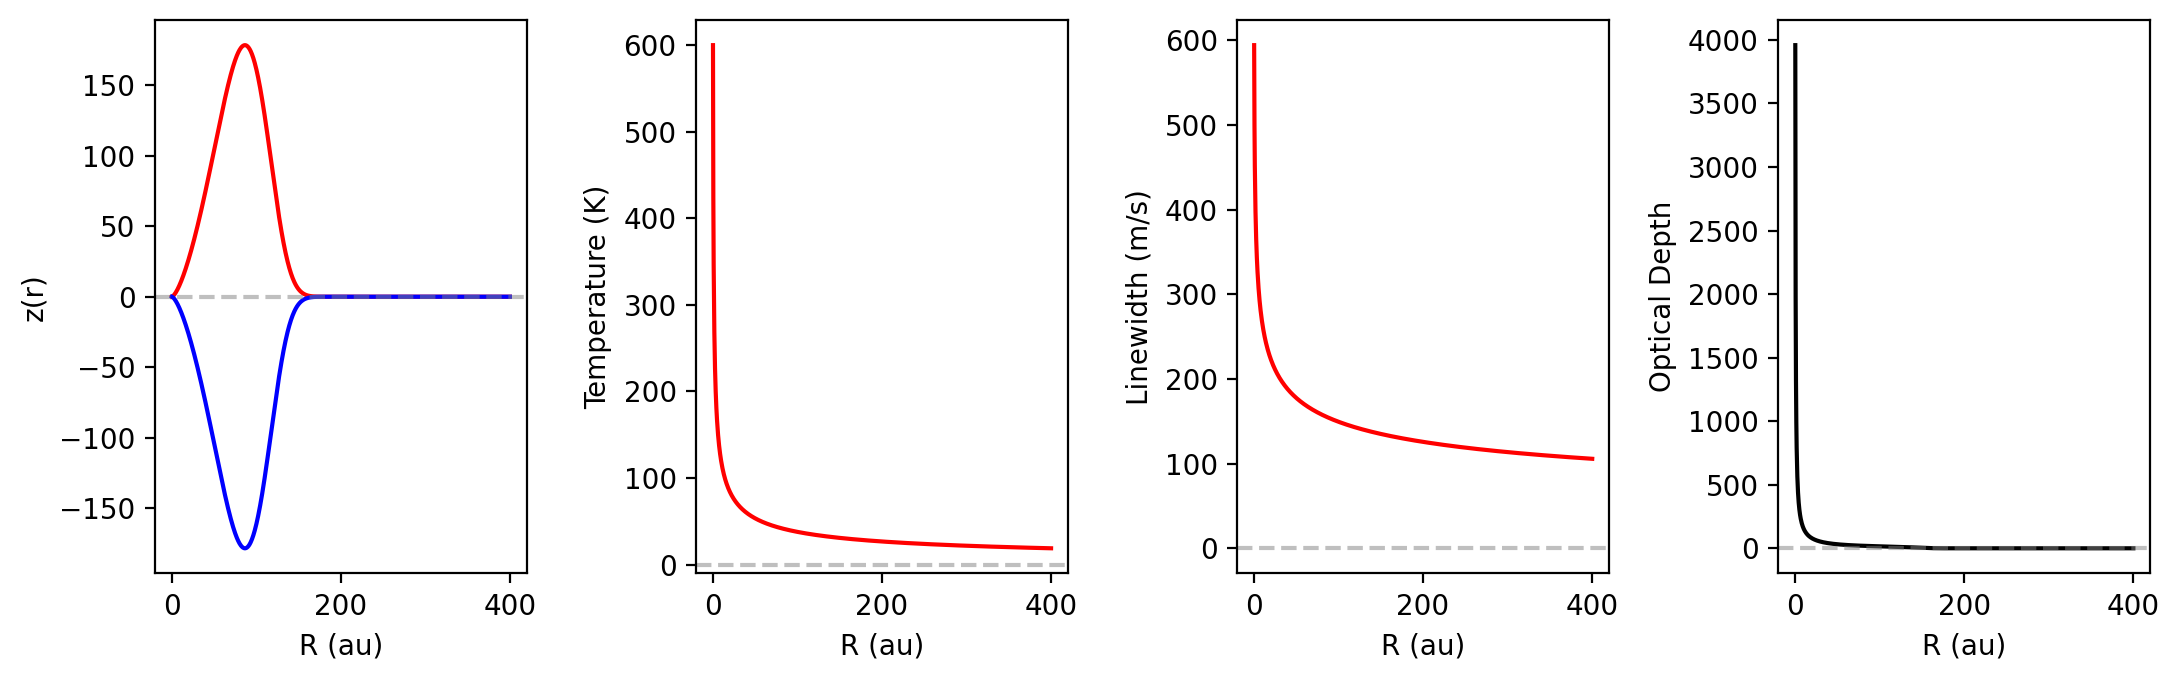

In [123]:
## DEMODISK PARAMETER 
theta = np.array([66.458, 162, 0.1 , 0.3 , 1.5, 
                  120, -0.5, 
                  110.083, 4.965, ## NEW
                  2.2, -1 , 
                  149.775, 9.984, 
                  12000,  0, 0])
#pars = theta

inc, PA, mstar, z_1, z_q, Tb_10, Tb_q, z_tap, z_exp, logtau_10, tau_q, tau_tap, tau_exp, vlsr, dx, dy = theta
r = np.linspace(0, 400, 1000)  # radius in au

fig, axs = plt.subplots(1, 4, figsize=(11, 3.5), dpi=200)
axs = axs.flatten()

axs[0].plot(r, z_f(r), color="red", label="New")
axs[0].plot(r, z_b(r), color="blue")


# --- Temperature ---
axs[1].plot(r, Tgas_Zallo(r), color="red")


# --- Linewidth ---
axs[2].plot(r, dV_Zallo(r), color="red")


# --- Optical depth ---
axs[3].plot(r, tau(r), color="black")


# --- Formatting ---
for ax in axs:
    #ax.set_xscale("log")
    ax.set_xlabel("R (au)")
    ax.axhline(0, color="gray", alpha=0.5, linestyle="--")

# Y-axis labels
axs[0].set_ylabel("z(r)")
axs[1].set_ylabel("Temperature (K)")
axs[2].set_ylabel("Linewidth (m/s)")
axs[3].set_ylabel("Optical Depth")

plt.tight_layout()
plt.show()

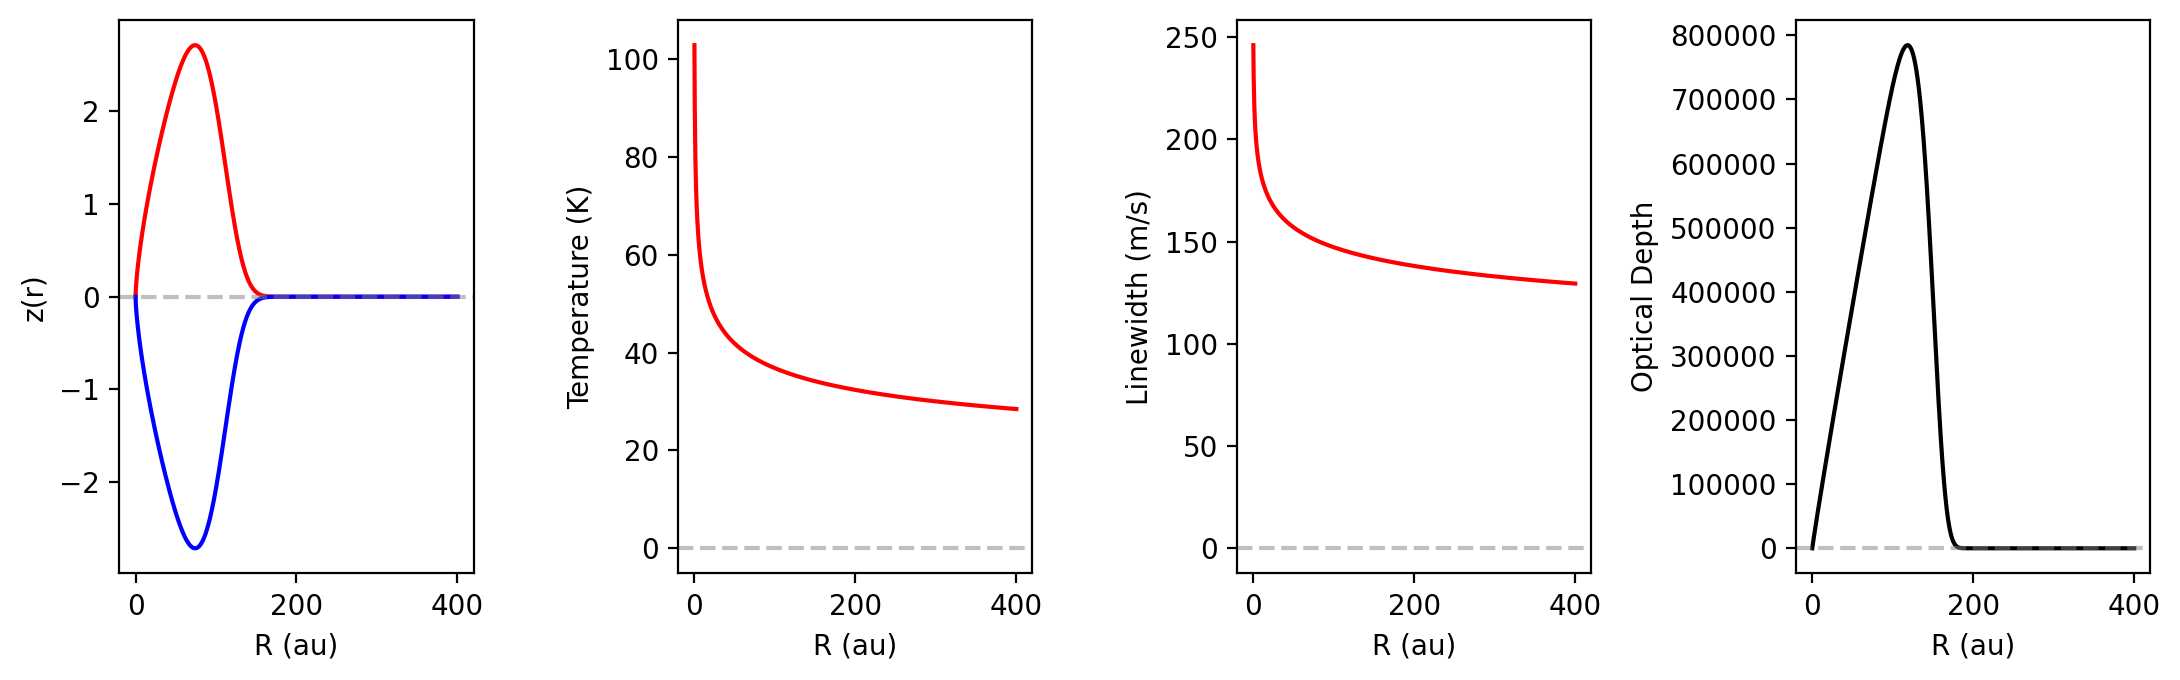

In [ ]:
theta = np.array([66.458, 324.447, 0.533, 0.158, 0.693, 
                  56.513, -0.186, 110.083, 4.965, 
                  4.909, 0.957, 149.775, 9.984, 12162.681,  -0.016, 0.007])
#pars = theta

inc, PA, mstar, z_1, z_q, \
Tb_10, Tb_q, z_tap, z_exp, \
        logtau_10, tau_q, tau_tap, tau_exp, vlsr, dx, dy = theta
r = np.linspace(0, 400, 1000)  # radius in au

fig, axs = plt.subplots(1, 4, figsize=(11, 3.5), dpi=200)
axs = axs.flatten()

axs[0].plot(r, z_f(r), color="red", label="New")
axs[0].plot(r, z_b(r), color="blue")


# --- Temperature ---
axs[1].plot(r, Tgas_Zallo(r), color="red")


# --- Linewidth ---
axs[2].plot(r, dV_Zallo(r), color="red")


# --- Optical depth ---
axs[3].plot(r, tau(r), color="black")


# --- Formatting ---
for ax in axs:
    #ax.set_xscale("log")
    ax.set_xlabel("R (au)")
    ax.axhline(0, color="gray", alpha=0.5, linestyle="--")

# Y-axis labels
axs[0].set_ylabel("z(r)")
axs[1].set_ylabel("Temperature (K)")
axs[2].set_ylabel("Linewidth (m/s)")
axs[3].set_ylabel("Optical Depth")

plt.tight_layout()
plt.show()

### Create 3D model structure using the parameters

In [ ]:
theta = np.array([66.458, 324.447, 0.533, 0.158, 0.693, 
                  56.513, -0.186, 110.083, 4.965, 
                  4.909, 0.957, 149.775, 9.984, 12162.681,  -0.016, 0.007])
#pars = theta

inc, PA, mstar, z_1, z_q, \
Tb_10, Tb_q, z_tap, z_exp, \
        logtau_10, tau_q,tau_tap, tau_exp, vlsr, dx, dy = theta

from csalt.csalt_disk import csalt_disk 

disk = csalt_disk()
disk.set_sky_coords(FOV=5.11, npix=512)
x0, y0 = dx, dy

disk.set_disk_coords(dx=x0, dy=y0, incl=inc, PA=PA, dist=dist,
                        z_func=z_f, side='front')

disk.set_disk_coords(dx=x0, dy=y0, incl=inc, PA=PA, dist=dist,
                        z_func=z_b, side='back')

Tmax_f = 1000
dVmax_f = np.sqrt(2 * sc.k * Tmax_f / (28 * (sc.m_p + sc.m_e)))
dVmax_b = np.sqrt(2 * sc.k * Tmax_f / (28 * (sc.m_p + sc.m_e)))
x0, y0 = dx, dy


disk.set_Tgas_profile(function=Tgas, vmin=0.0, vmax=Tmax_f, side='front')
disk.set_Tgas_profile(function=Tgas, vmin=0.0, vmax=Tmax_f, side='back')
disk.set_dV_profile(function=dV, vmin=0.0, vmax=dVmax_f, side='front')
disk.set_dV_profile(function=dV, vmin=0.0, vmax=dVmax_b, side='back')
disk.set_tau_profile(function=tau, vmin=0.0, vmax=None, side='both')


def vkep(r):
    """Keplerian rotational velocity profile in [m/s]."""
    r_m, z_m = r * sc.au, z_f(r / dist) * dist * sc.au
    vv = np.sqrt(sc.G * mstar * 1.98847e30 * r_m**2 / \
                    np.power(r_m**2 + z_m**2, 1.5))
    return vv

disk.set_vtheta_profile(function=vkep, side='both')
vlsr   = 12000.                          # systemic velocity [m/s]
dv     = 1000.                              # channel width [m/s]
nchan  = 23                               # number of channels
velax  = vlsr + dv * (np.arange(nchan) - nchan // 2)  # [m/s]
rest_freq  = '345.7959899GHz'  # rest frequency of the line (12CO 3-2)
rest_freq_Hz  = 345.7959899e9  # rest frequency of the line (12CO 3-2)

cube = disk.get_cube(velax=velax, restfreq=rest_freq_Hz, vlsr=vlsr)
cube = np.nan_to_num(cube)

(512, 512)

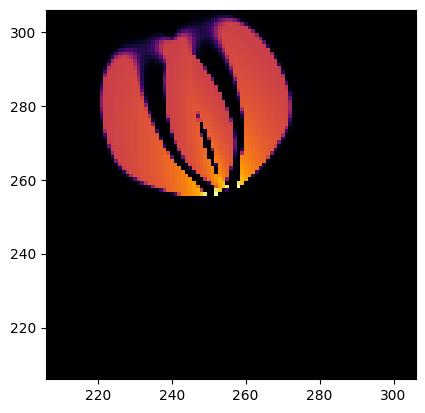

In [120]:
plt.imshow(cube[10], origin='lower', cmap='inferno')
nz, nx, ny = np.shape(cube)
plt.xlim(nx/2-50, nx/2+50)
plt.ylim(ny/2-50, ny/2+50)
nx, ny

In [ ]:
## DEMODISK PARAMETER 
theta = np.array([66.458, 162, 0.1 , 0.3 , 1.5, 
                  120, -0.5, 
                  110.083, 4.965, ## NEW
                  2.2, -1 , 
                  149.775, 9.984, 
                  12000,  0, 0])
#pars = theta

inc, PA, mstar, z_1, z_q, Tb_10, Tb_q, z_tap, z_exp, logtau_10, tau_q, tau_tap, tau_exp, vlsr, dx, dy = theta

In [117]:
disk = csalt_disk()
disk.set_sky_coords(FOV=5.11, npix=512)
x0, y0 = dx, dy

disk.set_disk_coords(dx=x0, dy=y0, incl=inc, PA=PA, dist=dist,
                        z_func=z_f, side='front')

disk.set_disk_coords(dx=x0, dy=y0, incl=inc, PA=PA, dist=dist,
                        z_func=z_b, side='back')

Tmax_f = 1000
dVmax_f = np.sqrt(2 * sc.k * Tmax_f / (28 * (sc.m_p + sc.m_e)))
dVmax_b = np.sqrt(2 * sc.k * Tmax_f / (28 * (sc.m_p + sc.m_e)))
x0, y0 = dx, dy


disk.set_Tgas_profile(function=Tgas, vmin=0.0, vmax=Tmax_f, side='front')
disk.set_Tgas_profile(function=Tgas, vmin=0.0, vmax=Tmax_f, side='back')
disk.set_dV_profile(function=dV, vmin=0.0, vmax=dVmax_f, side='front')
disk.set_dV_profile(function=dV, vmin=0.0, vmax=dVmax_b, side='back')
disk.set_tau_profile(function=tau, vmin=0.0, vmax=None, side='both')


def vkep(r):
    """Keplerian rotational velocity profile in [m/s]."""
    r_m, z_m = r * sc.au, z_f(r / dist) * dist * sc.au
    vv = np.sqrt(sc.G * mstar * 1.98847e30 * r_m**2 / \
                    np.power(r_m**2 + z_m**2, 1.5))
    return vv

disk.set_vtheta_profile(function=vkep, side='both')
vlsr   = 12000.                          # systemic velocity [m/s]
dv     = 1000.                              # channel width [m/s]
nchan  = 23                               # number of channels
velax  = vlsr + dv * (np.arange(nchan) - nchan // 2)  # [m/s]
rest_freq  = '345.7959899GHz'  # rest frequency of the line (12CO 3-2)
rest_freq_Hz  = 345.7959899e9  # rest frequency of the line (12CO 3-2)

cube = disk.get_cube(velax=velax, restfreq=rest_freq_Hz, vlsr=vlsr)
cube = np.nan_to_num(cube)

(512, 512)

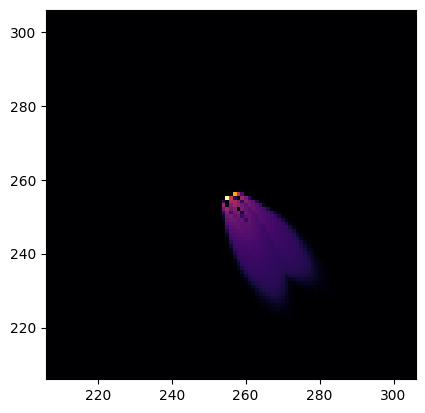

In [118]:
plt.imshow(cube[10], origin='lower', cmap='inferno')
nz, nx, ny = np.shape(cube)
plt.xlim(nx/2-50, nx/2+50)
plt.ylim(ny/2-50, ny/2+50)
nx, ny